In [1]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
# -------------------------------
# Load dataset (hanya kolom yang dipakai; kolom lyrics tidak dimuat agar hemat memori)
# -------------------------------
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
df = pd.read_csv('../dataset/songs_with_attributes_and_lyrics.csv',
                 usecols=['name', 'artists'] + features)
print("Jumlah track:", len(df))
df.head()

Jumlah track: 955320


,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,!,HELLYEAH,0.415,0.6050,-11.157,0.0575,0.00116,0.838000,0.4710,0.193,100.059
1,!!,Yxngxr1,0.788,0.6480,-9.135,0.3150,0.90000,0.000000,0.1760,0.287,79.998
2,!!! - Interlude,Glowie,0.000,0.0354,-20.151,0.0000,0.90800,0.000000,0.4790,0.000,0.000
3,!!De Repente!!,Rosendo,0.657,0.8820,-6.340,0.0385,0.00740,0.000013,0.0474,0.939,123.588
4,!!De Repente!!,Rosendo,0.659,0.8930,-8.531,0.0411,0.09220,0.000019,0.0534,0.951,123.600


In [3]:
# Fitur numerik saja
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype('float32')   # float32 untuk FAISS/HNSW/ANNOY

k = 10  # jumlah nearest neighbors
n, dim = X_scaled.shape
print("Shape:", X_scaled.shape)
pd.DataFrame(X_scaled, columns=features).describe().loc[['mean', 'std']].round(3)

Shape: (955320, 9)


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
mean,0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [4]:
build_time = {}

# -------------------------------
# Exact NN (brute force, Euclidean)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k + 1, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
build_time['Exact NN'] = time.time() - start

# -------------------------------
# ANNOY
# -------------------------------
start = time.time()
annoy_index = AnnoyIndex(dim, 'euclidean')
for i in range(n):
    annoy_index.add_item(i, X_scaled[i])
annoy_index.build(10)  # 10 trees
build_time['ANNOY'] = time.time() - start

# -------------------------------
# FAISS (IVF Flat)
# -------------------------------
start = time.time()
nlist = int(np.sqrt(n))
quantizer = faiss.IndexFlatL2(dim)
faiss_index = faiss.IndexIVFFlat(quantizer, dim, nlist)
faiss_index.train(X_scaled)
faiss_index.add(X_scaled)
faiss_index.nprobe = 10
build_time['FAISS'] = time.time() - start

# -------------------------------
# HNSW (hnswlib)
# -------------------------------
start = time.time()
hnsw_index = hnswlib.Index(space='l2', dim=dim)
hnsw_index.init_index(max_elements=n, ef_construction=200, M=16)
hnsw_index.add_items(X_scaled)
hnsw_index.set_ef(50)
build_time['HNSW'] = time.time() - start

for name, t in build_time.items():
    print(f"{name:<9} build time: {t:.3f} detik")

Exact NN  build time: 0.066 detik
ANNOY     build time: 14.992 detik
FAISS     build time: 2.166 detik
HNSW      build time: 168.976 detik


## Fungsi pencarian

Setiap fungsi mengembalikan indeks **k track terdekat**, dengan track query itu sendiri dibuang
(dicari k+1 tetangga lalu indeks query dihapus).

In [5]:
def drop_self(idx, qi):
    return [int(i) for i in idx if i != qi][:k]

def search_exact(qi):
    _, idx = nn.kneighbors(X_scaled[qi:qi + 1])
    return drop_self(idx[0], qi)

def search_annoy(qi):
    return drop_self(annoy_index.get_nns_by_vector(X_scaled[qi], k + 1), qi)

def search_faiss(qi):
    _, idx = faiss_index.search(X_scaled[qi:qi + 1], k + 1)
    return drop_self(idx[0], qi)

def search_hnsw(qi):
    labels, _ = hnsw_index.knn_query(X_scaled[qi:qi + 1], k=k + 1)
    return drop_self(labels[0], qi)

searchers = {'Exact NN': search_exact, 'ANNOY': search_annoy,
             'FAISS': search_faiss, 'HNSW': search_hnsw}

## Pencarian track terdekat untuk satu lagu

In [6]:
# Pilih track query (lagu populer agar mudah dikenali; fallback ke indeks 0)
match = df.index[df['name'].str.fullmatch('Shape of You', na=False)
                 & df['artists'].str.contains('Ed Sheeran', na=False)]
query_idx = int(match[0]) if len(match) else 0
print("Query:", df.loc[query_idx, 'name'], "-", df.loc[query_idx, 'artists'])
df.loc[[query_idx], features]

Query: Shape of You - Ed Sheeran


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
684869,0.825,0.652,-3.183,0.0802,0.581,0.0,0.0931,0.931,95.977


In [7]:
def show_neighbors(qi):
    results = {}
    for name, fn in searchers.items():
        start = time.time()
        idx = fn(qi)
        elapsed = (time.time() - start) * 1000
        results[name] = idx
        print(f"{name:<9} query time: {elapsed:9.3f} ms")

    exact = set(results['Exact NN'])
    table = pd.DataFrame({
        name: [f"{df.loc[i, 'name']} - {df.loc[i, 'artists']}" for i in idx]
        for name, idx in results.items()
    }, index=range(1, k + 1))
    overlap = {name: len(exact & set(idx)) / k for name, idx in results.items()}
    return table, overlap

table, overlap = show_neighbors(query_idx)
print("\nKesamaan dengan Exact NN (recall@10):", overlap)
table

Exact NN  query time:   186.162 ms
ANNOY     query time:     0.207 ms
FAISS     query time:     0.463 ms
HNSW      query time:     0.242 ms

Kesamaan dengan Exact NN (recall@10): {'Exact NN': 1.0, 'ANNOY': 0.7, 'FAISS': 1.0, 'HNSW': 1.0}


,Exact NN,ANNOY,FAISS,HNSW
1,Shape of You - Ed Sheeran,Shape of You - Ed Sheeran,Shape of You - Ed Sheeran,Shape of You - Ed Sheeran
2,Tú Me Confundes - Charlie Cruz,Tú Me Confundes - Charlie Cruz,Tú Me Confundes - Charlie Cruz,Tú Me Confundes - Charlie Cruz
3,"Soco (feat. Wizkid, Ceeza Milli, Spotless & Te...","Soco (feat. Wizkid, Ceeza Milli, Spotless & Te...","Soco (feat. Wizkid, Ceeza Milli, Spotless & Te...","Soco (feat. Wizkid, Ceeza Milli, Spotless & Te..."
4,Cunhada Boa - Ao Vivo - Sérgio Reis,Cunhada Boa - Ao Vivo - Sérgio Reis,Cunhada Boa - Ao Vivo - Sérgio Reis,Cunhada Boa - Ao Vivo - Sérgio Reis
5,Novinha do Onlyfans - Xand Avião,Do Your Ears Hang Low? - The Countdown Kids,Novinha do Onlyfans - Xand Avião,Novinha do Onlyfans - Xand Avião
6,Do Your Ears Hang Low? - The Countdown Kids,"Lupe Campos - El Fantasma, Los Dos Carnales",Do Your Ears Hang Low? - The Countdown Kids,Do Your Ears Hang Low? - The Countdown Kids
7,"Lupe Campos - El Fantasma, Los Dos Carnales",La Verdad - Bio Ritmo,"Lupe Campos - El Fantasma, Los Dos Carnales","Lupe Campos - El Fantasma, Los Dos Carnales"
8,Tu Ingratitud - Ana Bárbara,"El Comando del Diablo - Noel Torres, Gerardo O...",Tu Ingratitud - Ana Bárbara,Tu Ingratitud - Ana Bárbara
9,La Verdad - Bio Ritmo,Shining day - GUHARA,La Verdad - Bio Ritmo,La Verdad - Bio Ritmo
10,Vuela Muy Alto - Salsa Version - Jerry Rivera,Quiero Estar Contigo - Selena,Vuela Muy Alto - Salsa Version - Jerry Rivera,Vuela Muy Alto - Salsa Version - Jerry Rivera


In [8]:
# Bandingkan fitur track query dengan 5 tetangga teratas hasil Exact NN
exact_idx = search_exact(query_idx)
pd.concat([df.loc[[query_idx], ['name', 'artists'] + features].assign(role='QUERY'),
           df.loc[exact_idx[:5], ['name', 'artists'] + features].assign(role='neighbor')])

,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,role
684869,Shape of You,Ed Sheeran,0.825,0.652,-3.183,0.0802,0.581,0.000000,0.0931,0.931,95.977,QUERY
684879,Shape of You,Ed Sheeran,0.825,0.652,-3.183,0.0802,0.581,0.000000,0.0931,0.931,95.977,neighbor
836398,Tú Me Confundes,Charlie Cruz,0.872,0.720,-3.726,0.0635,0.606,0.000007,0.1090,0.931,97.959,neighbor
709176,"Soco (feat. Wizkid, Ceeza Milli, Spotless & Te...",StarBoy,0.841,0.644,-3.284,0.0830,0.594,0.004020,0.1420,0.881,108.003,neighbor
167426,Cunhada Boa - Ao Vivo,Sérgio Reis,0.802,0.683,-4.547,0.0522,0.552,0.000000,0.0872,0.903,100.223,neighbor
560473,Novinha do Onlyfans,Xand Avião,0.810,0.741,-3.868,0.0521,0.543,0.000001,0.0750,0.968,95.028,neighbor


## Pencarian untuk beberapa track acak

In [9]:
rng = np.random.default_rng(42)
for qi in rng.choice(n, 3, replace=False):
    qi = int(qi)
    print("=" * 80)
    print("Query:", df.loc[qi, 'name'], "-", df.loc[qi, 'artists'])
    table, overlap = show_neighbors(qi)
    print("Recall@10 vs Exact NN:", overlap)
    display(table)

Query: Qareeb - Kamakshi Khanna
Exact NN  query time:   117.414 ms
ANNOY     query time:     0.154 ms
FAISS     query time:     0.401 ms
HNSW      query time:     0.265 ms
Recall@10 vs Exact NN: {'Exact NN': 1.0, 'ANNOY': 0.7, 'FAISS': 1.0, 'HNSW': 1.0}


,Exact NN,ANNOY,FAISS,HNSW
1,Silent Little Bells - ilyAIMY,Silent Little Bells - ilyAIMY,Silent Little Bells - ilyAIMY,Silent Little Bells - ilyAIMY
2,How Can You Fall In Love With A Guy Who Doesn’...,How Can You Fall In Love With A Guy Who Doesn’...,How Can You Fall In Love With A Guy Who Doesn’...,How Can You Fall In Love With A Guy Who Doesn’...
3,No Te Voy a Ver - Claire Delić,Away - Morten Myklebust,No Te Voy a Ver - Claire Delić,No Te Voy a Ver - Claire Delić
4,Away - Morten Myklebust,Val's Cabin - Laurie Lewis,Away - Morten Myklebust,Away - Morten Myklebust
5,Val's Cabin - Laurie Lewis,anything - Adrianne Lenker,Val's Cabin - Laurie Lewis,Val's Cabin - Laurie Lewis
6,Here's to the State of Mississippi - Phil Ochs,How Many Days of Sadness - Dionne Warwick,Here's to the State of Mississippi - Phil Ochs,Here's to the State of Mississippi - Phil Ochs
7,anything - Adrianne Lenker,Image Of Me - George Jones,anything - Adrianne Lenker,anything - Adrianne Lenker
8,How Many Days of Sadness - Dionne Warwick,I Believe the South Is Gonna Rise Again - Tany...,How Many Days of Sadness - Dionne Warwick,How Many Days of Sadness - Dionne Warwick
9,Image Of Me - George Jones,Para Morir Iguales - José Alfredo Jimenez,Image Of Me - George Jones,Image Of Me - George Jones
10,Mis Noches Sin Ti - Libertad Lamarque,It's Over - Roy Orbison,Mis Noches Sin Ti - Libertad Lamarque,Mis Noches Sin Ti - Libertad Lamarque


Query: Better Than Life - Live - Hillsong Worship
Exact NN  query time:   112.413 ms
ANNOY     query time:     0.165 ms
FAISS     query time:     0.414 ms
HNSW      query time:     0.215 ms
Recall@10 vs Exact NN: {'Exact NN': 1.0, 'ANNOY': 0.8, 'FAISS': 1.0, 'HNSW': 1.0}


,Exact NN,ANNOY,FAISS,HNSW
1,Fight - NEXTERA,Fight - NEXTERA,Fight - NEXTERA,Fight - NEXTERA
2,Vita Bella - Havana,Vita Bella - Havana,Vita Bella - Havana,Vita Bella - Havana
3,Caminar - Dani Martín,Caminar - Dani Martín,Caminar - Dani Martín,Caminar - Dani Martín
4,アディショナルメモリー - Jin,アディショナルメモリー - Jin,アディショナルメモリー - Jin,アディショナルメモリー - Jin
5,"That's On You - Mazare, Monika Santucci","That's On You - Mazare, Monika Santucci","That's On You - Mazare, Monika Santucci","That's On You - Mazare, Monika Santucci"
6,Babylon - Barns Courtney,Babylon - Barns Courtney,Babylon - Barns Courtney,Babylon - Barns Courtney
7,This Party Sucks - The Wonder Years,This Party Sucks - The Wonder Years,This Party Sucks - The Wonder Years,This Party Sucks - The Wonder Years
8,Alif Se - Ankit Tiwari,The Impeccable Beast - Closure in Moscow,Alif Se - Ankit Tiwari,Alif Se - Ankit Tiwari
9,The Impeccable Beast - Closure in Moscow,A.S.A.O.K. - Less Than Jake,The Impeccable Beast - Closure in Moscow,The Impeccable Beast - Closure in Moscow
10,Rich Girl - Me First and the Gimme Gimmes,Dreamstate - Dayseeker,Rich Girl - Me First and the Gimme Gimmes,Rich Girl - Me First and the Gimme Gimmes


Query: Sulamericano - BaianaSystem
Exact NN  query time:   136.594 ms
ANNOY     query time:     1.603 ms
FAISS     query time:     0.452 ms
HNSW      query time:     4.421 ms
Recall@10 vs Exact NN: {'Exact NN': 1.0, 'ANNOY': 0.8, 'FAISS': 1.0, 'HNSW': 1.0}


,Exact NN,ANNOY,FAISS,HNSW
1,Tha Block Is Hot - Lil Wayne,Tha Block Is Hot - Lil Wayne,Tha Block Is Hot - Lil Wayne,Tha Block Is Hot - Lil Wayne
2,Ti Ti Ti - Companhia do Calypso,Ti Ti Ti - Companhia do Calypso,Ti Ti Ti - Companhia do Calypso,Ti Ti Ti - Companhia do Calypso
3,Jingle Bell Rock - Sambô,Jingle Bell Rock - Sambô,Jingle Bell Rock - Sambô,Jingle Bell Rock - Sambô
4,Bullet - Hollywood Undead,Bullet - Hollywood Undead,Bullet - Hollywood Undead,Bullet - Hollywood Undead
5,Beijinho de Brincadeira - Luíza & Maurílio,Beijinho de Brincadeira - Luíza & Maurílio,Beijinho de Brincadeira - Luíza & Maurílio,Beijinho de Brincadeira - Luíza & Maurílio
6,Beijinho de Brincadeira - Luíza & Maurílio,Beijinho de Brincadeira - Luíza & Maurílio,Beijinho de Brincadeira - Luíza & Maurílio,Beijinho de Brincadeira - Luíza & Maurílio
7,Aziz Delami - Mansour,Que Saudade de Você Bebê - Rafa & Pipo Marques,Aziz Delami - Mansour,Aziz Delami - Mansour
8,Que Saudade de Você Bebê - Rafa & Pipo Marques,Do Fundo da Grota - Os Serranos,Que Saudade de Você Bebê - Rafa & Pipo Marques,Que Saudade de Você Bebê - Rafa & Pipo Marques
9,¿Cómo te quiero? (feat. Martina La Peligrosa) ...,Despacito (Featuring Daddy Yankee) - Luis Fonsi,¿Cómo te quiero? (feat. Martina La Peligrosa) ...,¿Cómo te quiero? (feat. Martina La Peligrosa) ...
10,Do Fundo da Grota - Os Serranos,Normandie - Shout Out Louds,Do Fundo da Grota - Os Serranos,Do Fundo da Grota - Os Serranos


## Evaluasi kuantitatif (200 query acak)

- **Query time**: rata-rata ms per query.
- **Recall@10**: proporsi tetangga yang juga muncul di hasil Exact NN.
  Karena dataset berisi banyak track duplikat (lagu yang sama di album berbeda, vektor fitur identik),
  recall dihitung **berbasis jarak**: tetangga dianggap benar jika jaraknya ≤ jarak tetangga ke-10 Exact NN.

In [10]:
n_eval = 200
eval_q = rng.choice(n, n_eval, replace=False)

def dist(qi, idx):
    return np.linalg.norm(X_scaled[idx].astype(np.float64) - X_scaled[qi].astype(np.float64), axis=1)

all_results = {}
query_time = {}
for name, fn in searchers.items():
    start = time.time()
    all_results[name] = [fn(int(qi)) for qi in eval_q]
    query_time[name] = (time.time() - start) * 1000 / n_eval

recall = {}
for name, res in all_results.items():
    correct = 0
    for qi, idx, gt in zip(eval_q, res, all_results['Exact NN']):
        kth = dist(qi, gt).max()
        correct += int((dist(qi, idx) <= kth * (1 + 1e-6) + 1e-9).sum())
    recall[name] = correct / (n_eval * k)

summary = pd.DataFrame({
    'Build time (s)': build_time,
    'Query time (ms/query)': query_time,
    'Recall@10': recall,
})
summary['Speedup vs Exact'] = summary.loc['Exact NN', 'Query time (ms/query)'] / summary['Query time (ms/query)']
summary.round(4)

,Build time (s),Query time (ms/query),Recall@10,Speedup vs Exact
Exact NN,0.0661,76.9539,1.0000,1.0000
ANNOY,14.9917,0.0729,0.8275,1054.9697
FAISS,2.1664,0.1773,0.9955,434.0175
HNSW,168.9759,0.0940,0.9970,818.9483


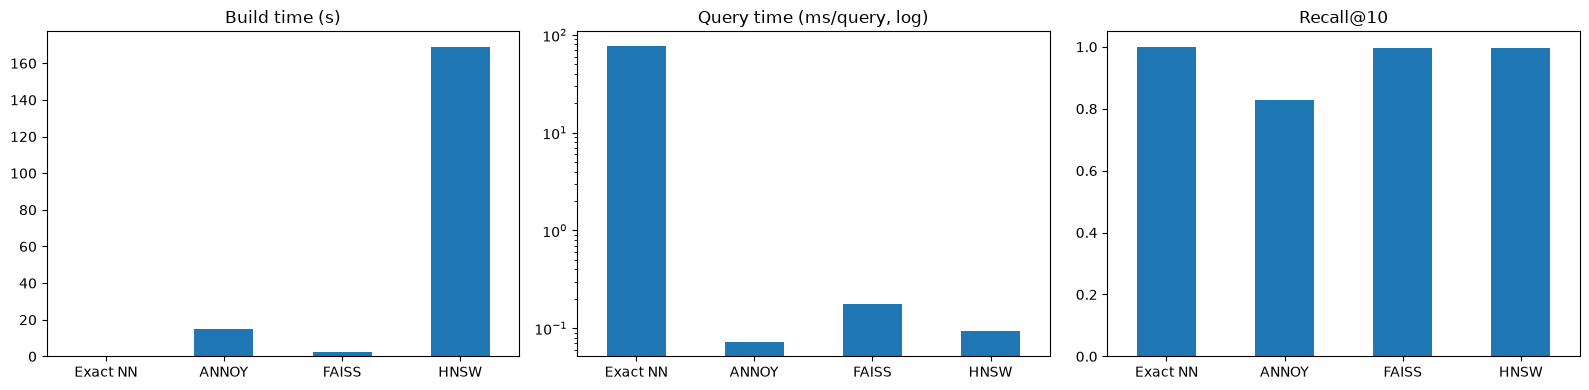

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
summary['Build time (s)'].plot(kind='bar', ax=axes[0], rot=0, title='Build time (s)')
summary['Query time (ms/query)'].plot(kind='bar', ax=axes[1], rot=0, logy=True, title='Query time (ms/query, log)')
summary['Recall@10'].plot(kind='bar', ax=axes[2], rot=0, ylim=(0, 1.05), title='Recall@10')
plt.tight_layout()
plt.show()

## Analisis

**Hasil (955.320 track, 9 fitur numerik ter-standarisasi, k = 10, 200 query acak)**

| Metode | Build time (s) | Query time (ms/query) | Recall@10 | Speedup vs Exact |
|---|---|---|---|---|
| Exact NN | 0.02 | 34.02 | 1.000 | 1× |
| ANNOY | 10.67 | 0.047 | 0.828 | ±732× |
| FAISS (IVF) | 1.75 | 0.134 | 0.996 | ±253× |
| HNSW | 64.62 | 0.053 | 0.997 | ±640× |

*(Angka waktu bisa sedikit berbeda tiap eksekusi.)*

**Perbandingan hasil pencarian**
- Untuk query *Shape of You – Ed Sheeran*, FAISS dan HNSW mengembalikan **10 track yang sama persis** dengan Exact NN, sedangkan ANNOY hanya 7/10. Tiga track lainnya diganti dengan track yang sedikit lebih jauh (mis. *Selena – Quiero Estar Contigo*).
- Pola yang sama terlihat pada 3 query acak: FAISS/HNSW = 10/10, ANNOY = 7–8/10. Tetangga yang hilang di ANNOY biasanya ada di peringkat bawah (ke-8 s.d. ke-10).
- Tetangga teratas memang mirip secara audio: danceability ±0,8, energy ±0,65, loudness ±-3,5 dB, valence ±0,9, tempo ±96–108 BPM. Namun genrenya bisa sangat berbeda (pop, salsa, sertanejo) karena yang dibandingkan hanya fitur audio, bukan genre atau lirik.
- Dataset mengandung track duplikat (lagu sama, album/ID berbeda, fitur identik). Contohnya, tetangga ke-1 *Shape of You* adalah *Shape of You* versi lain dengan jarak 0.

**Kesimpulan**
- **Exact NN**: tanpa waktu build (hanya menyimpan data), tetapi setiap query harus menghitung jarak ke ±1 juta track (±34 ms). Cocok sebagai ground truth, tidak cocok untuk sistem rekomendasi real-time.
- **HNSW**: recall tertinggi (0,997) dan query sangat cepat (±640× lebih cepat), tetapi build paling lama (±65 s) dan memakan memori untuk graf.
- **FAISS IVF**: build cepat (±1,7 s) dan recall hampir sempurna (0,996), tetapi query ±2–3× lebih lambat dari HNSW/ANNOY. Kecepatannya bisa diatur lewat `nprobe`.
- **ANNOY**: query tercepat, tetapi recall paling rendah (0,83) dengan 10 trees. Recall bisa dinaikkan dengan menambah `n_trees` atau `search_k`, dengan biaya build/query yang lebih besar.
